Code for Time and Severity Visuals

In [1]:
# Import python libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Load the cleaned dataset
df_clean = pd.read_csv('TimeSeverityColumns.csv')

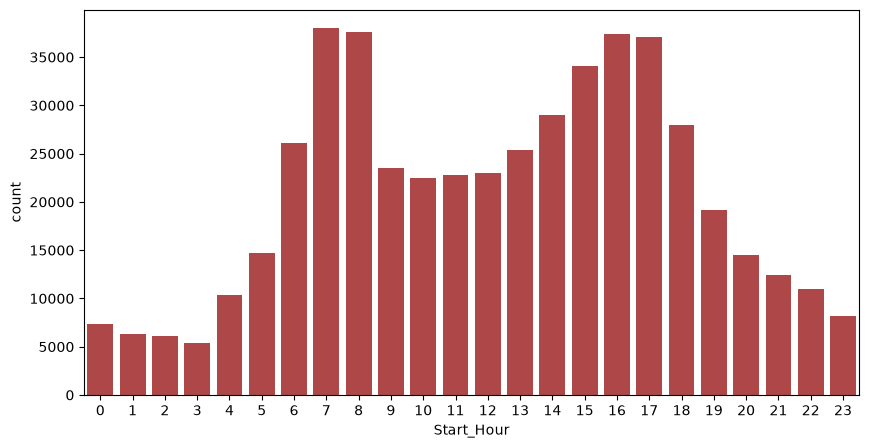

In [3]:
# Simple Visual Showing the distribution of accidents by time of day (Start_Hour)
plt.figure(figsize=(10, 5))
sns.countplot(data=df_clean, x='Start_Hour', color='#bf3636')

plt.show()

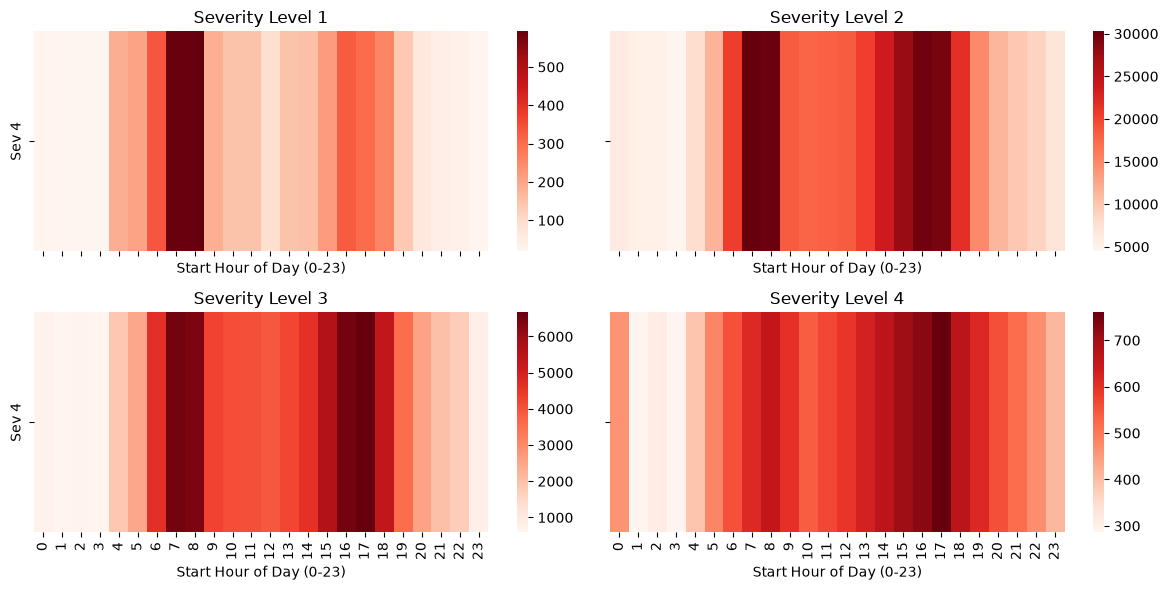

In [ ]:
# Create heatmap for each severity level across the 24 hours of the day
severityLevels = [1, 2, 3, 4] 

# Creates 4 subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
axes = axes.flatten()

for i, sevLevel in enumerate(severityLevels):
    
    # Filter data for this specific severity and count occurrences per hour
    subset = df_clean[df_clean['Severity'] == sevLevel]
    hour_counts = subset['Start_Hour'].value_counts().reindex(range(24), fill_value=0)
    
    # Reshapefor the heatmap function
    mat = hour_counts.values.reshape(1, 24)
    
    # Plotheatmap
    sns.heatmap(
        mat, 
        ax=axes[i], 
        cmap='Reds', 
        cbar=True, 
        yticklabels=[f'Sev {sevLevel}'],
        xticklabels=range(24)
    )
    axes[i].set_title(f'Severity Level {sevLevel}')
    axes[i].set_xlabel('Start Hour of Day (0-23)')

plt.tight_layout()
plt.show()